In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

solves = pd.read_csv("results/solves.csv")
pw = pd.read_csv("results/pairwise.csv")
pw["pair"] = pw.solver_a + "-" + pw.solver_b
SOLVERS = ["Ipopt", "SNOPT", "NLopt"]
S_COLORS = {"Ipopt": "blue", "SNOPT": "green", "NLopt": "orange"}
joints = pd.read_csv("results/joints.csv")

In [ ]:
samp_methods = ["joint_space", "task_space"]
feas_colors = {True: "blue", False: "red"}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, method in zip(axes, samp_methods):
    d = solves[solves.generation_method == method]
    for i, s in enumerate(SOLVERS):
        g = d[d.solver_name == s]
        y = g.evaluated_cost.to_numpy()
        x = np.random.default_rng(0).normal(i, 0.06, size=len(y))  # jitter
        col = g.feasible.map(feas_colors).to_numpy()
        ax.scatter(x, y, s=14, alpha=0.5, color=col, edgecolor="none")
    ax.set_xticks(range(len(SOLVERS))); ax.set_xticklabels(SOLVERS)
    ax.set_title(method); ax.set_xlabel("solver")
axes[0].set_ylabel("evaluated_cost")
fig.tight_layout()

from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker="o", ls="", color=feas_colors[k],
                  label="feasible" if k else "infeasible") for k in (True, False)]
axes[1].legend(handles=handles, loc="upper right")

In [ ]:
pairs = ["Ipopt-SNOPT", "Ipopt-NLopt", "NLopt-SNOPT"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, pr in zip(axes, pairs):
    d = pw[(pw.pair == pr) & (pw.both_feasible) &
           (pw.generation_method == "joint_space")]
    sc = ax.scatter(d.evaluated_cost_a, d.evaluated_cost_b, s=18, alpha=0.6,
                    edgecolor="none")
    lo = np.nanmin([d.evaluated_cost_a.min(), d.evaluated_cost_b.min()])
    hi = np.nanmax([d.evaluated_cost_a.max(), d.evaluated_cost_b.max()])
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)  # y = x
    a, b = pr.split("-")
    ax.set_xlabel(f"{a} cost"); ax.set_ylabel(f"{b} cost"); ax.set_title(pr)
fig.suptitle("both-feasible, joint-space"); fig.tight_layout()

In [ ]:
solves["outcome"] = np.where(
    solves.error_type == "NonFiniteSolution", "NaN",
    np.where(solves.feasible, "feasible", "infeasible"))
order = ["feasible", "infeasible", "NaN"]
seg = {"feasible": "#2ca02c", "infeasible": "#ff7f0e", "NaN": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, world in zip(axes, ["joint_space", "task_space"]):
    d = solves[solves.generation_method == world]
    frac = (d.groupby("solver_name").outcome.value_counts(normalize=True)
              .unstack().reindex(index=SOLVERS, columns=order).fillna(0))
    bottom = np.zeros(len(SOLVERS))
    for o in order:
        ax.bar(SOLVERS, frac[o], bottom=bottom, color=seg[o], label=o)
        bottom += frac[o].to_numpy()
    ax.set_title(world); ax.set_ylabel("fraction of solves")
axes[0].legend(loc="lower left"); fig.tight_layout()

In [ ]:
d = pw[pw.both_feasible & (pw.generation_method == "joint_space")]
fig, ax = plt.subplots(figsize=(7, 5))
for pr, g in d.groupby("pair"):
    ax.scatter(g.q_diff_2, g.cost_diff_abs, s=16, alpha=0.5, label=pr)
ax.set_xlabel("q_diff_2 (rad)"); ax.set_ylabel("cost_diff_abs")
ax.legend(); fig.tight_layout()

In [ ]:

fig, ax = plt.subplots(figsize=(7, 5))
for pr, g in pw.groupby("pair"):
    ax.scatter(g.q_diff_2, g.cost_diff_abs, s=16, alpha=0.5, label=pr)
ax.set_xlabel("q_diff_2 (rad)"); ax.set_ylabel("cost_diff")
ax.legend(); fig.tight_layout()

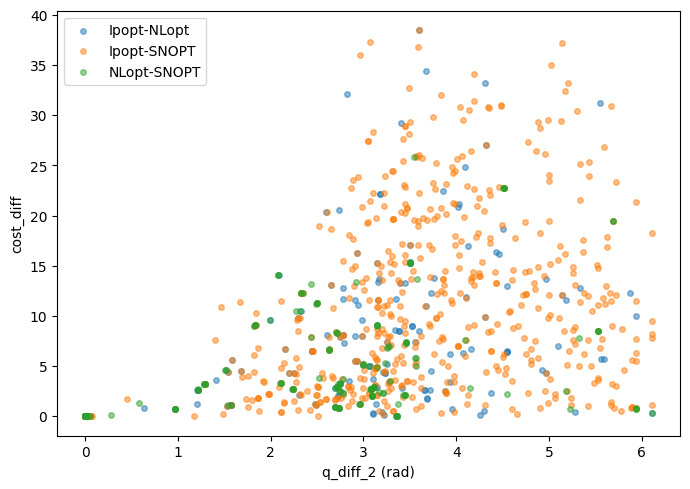

In [ ]:

fig, ax = plt.subplots(figsize=(7, 5))
for pr, g in pw.groupby("pair"):
    ax.scatter(g.q_diff_inf, g.cost_diff_abs, s=16, alpha=0.5, label=pr)
ax.set_xlabel("q_diff_inf (rad)"); ax.set_ylabel("cost_diff")
ax.legend(); fig.tight_layout()

In [ ]:
d = pw[pw.both_feasible & (pw.generation_method == "joint_space")]
fig, ax = plt.subplots(figsize=(7, 5))
for pr, g in d.groupby("pair"):
    ax.scatter(g.q_diff_2, g.cost_diff_rel, s=16, alpha=0.5, label=pr)
ax.set_xlabel("q_diff_2 (rad)"); ax.set_ylabel("cost_diff_rel")
ax.legend(); fig.tight_layout()

In [ ]:
feas = solves[(solves.feasible) & (solves["solver_name"].isin(["SNOPT", "Ipopt"])) & (solves.native_optimality < 0.8)]

fig, ax = plt.subplots(figsize=(7, 5))

col = ["blue" if c == "Ipopt" else "green" for c in feas.solver_name]

ax.scatter(feas.native_optimality, feas.common_residual_inf, 
           s=16, alpha=0.5, c=col)

ax.set_xlabel("native")
ax.set_ylabel("common")
ax.legend()
fig.tight_layout()

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for s in ["Ipopt", "SNOPT"]:
    g = solves[(solves.solver_name == s) &
               solves.native_optimality.notna() & solves.common_residual_inf.notna()]
    ax.scatter(g.native_optimality, g.common_residual_inf, s=16, alpha=0.5,
               color=S_COLORS[s], label=s)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("native_optimality")
ax.set_ylabel("common_residual_inf")
ax.plot(ax.get_xlim(), ax.get_xlim(), "k--", lw=0.6)  # y=x reference
ax.legend(); fig.tight_layout()

##### snopt's self-reported optimality is not comparable. fix this

In [ ]:
nat = solves[(solves.solver_name=="Ipopt") & (solves["native_optimality"]>1)]

print(len(nat))
print(len(nat[nat.orientation_tol > 0]))
print(len(nat[nat.orientation_tol == 0]))

print(nat['orientation_tol'].value_counts())

ip_ok = solves[(solves.solver_name == "Ipopt") & (solves.feasible)]
print(ip_ok.native_optimality.describe()[["50%", "max"]])


In [ ]:
# proportion with same q (within threshold)
print(len(pw[pw["same_q"]==True])/len(pw))

0.07604166666666666
